# TE mode and Bessel functions
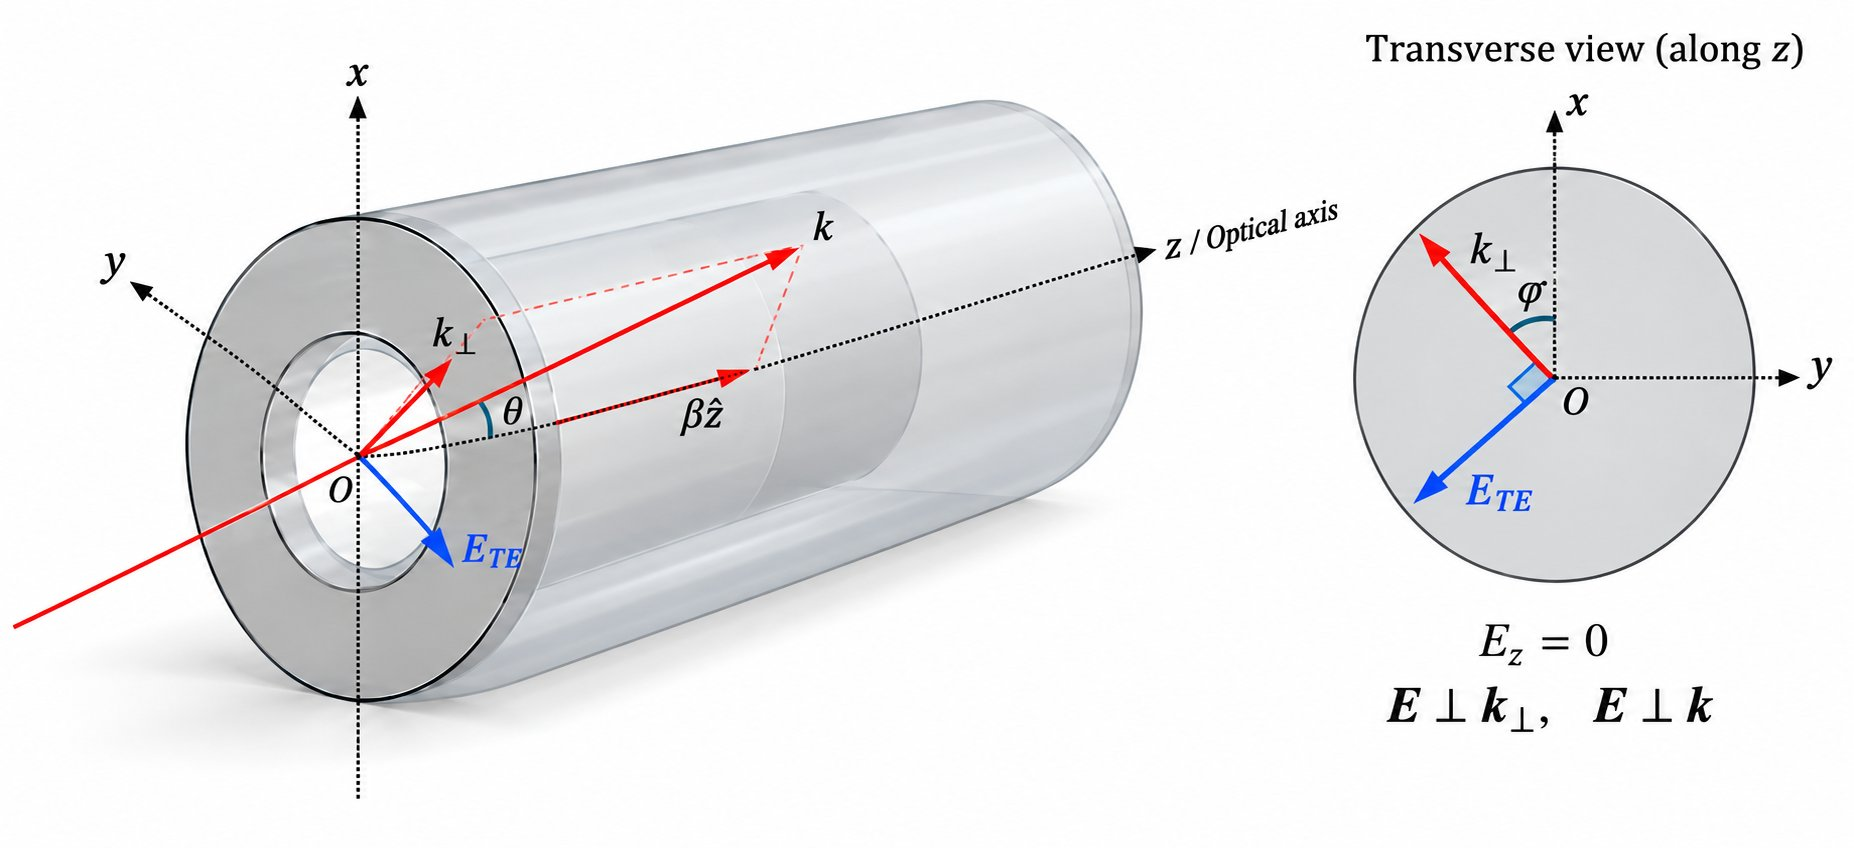


설명과 그림, 실행 코드를 이 노트북 하나에 담았다. 코드는 위에서 아래로 실행하고, 값을 바꾼 뒤 Shift+Enter로 다시 실행할 수 있다.


## 1. 좌표계와 파수 벡터

원통좌표를

$$
(r,\phi,z)
$$

라고 하자. 여기서

- $z$: 도파관의 축 방향
- $r$: 축으로부터의 거리
- $\phi$: 횡단면 내의 방위각

이다.

균일한 코어 안의 각 평면파 성분에 대해서는 파수 벡터를 축 방향 성분과 횡방향 성분으로 나누어

$$
\mathbf{k}=\mathbf{k}_\perp+\beta \hat z
$$

라고 쓸 수 있다. 원통 대칭적인 논의에서는 횡파수의 크기를 $k_r$라고 쓰고,

$$
k_r=nk_0\sin\theta,\qquad
\beta=nk_0\cos\theta
$$

라고 둘 수 있다. 여기서 $\theta$는 파수 벡터 $\mathbf{k}$와 $z$축이 이루는 각이다. 따라서 $\theta$는 “파동이 도파관 축에 대해 얼마나 기울어져 있는가”를 나타낸다.


In [ ]:
# 그래프를 실행하려면 이 셀부터 실행하세요.
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j0, j1

k_r = 1.0     # 횡파수: 값을 바꿔 보세요.
r_max = 10.0  # 그래프에 표시할 반지름 범위
r = np.linspace(0, r_max, 500)


## 2. TE 모드의 의미

TE 모드란 축 방향 전기장 성분이 0인 모드, 즉

$$
E_z=0
$$

을 만족하는 모드이다. 따라서 도파관 안의 전기장은 파이버의 횡단면과 평행하다.
또한 

$$
\mathbf{k}=\mathbf{k}_\perp+\beta \hat z
$$

이므로, 균일한 매질의 각 평면파 성분에 대해 $\mathbf{k} \cdot \mathbf{E} = \mathbf{k}_\perp \cdot \mathbf{E} + \beta \hat z  \cdot \mathbf{E} = \mathbf{k}_\perp \cdot \mathbf{E} = 0$

즉 $\mathbf{E}$ 의 방향은 $\mathbf{k}$, $\mathbf{k}_\perp$ 가 이루는 평면에 수직이다.

$$
\mathbf{k}_\perp = k_r \hat {\mathbf {r}}
$$

라고 한다면, 전기장의 방향은 $\hat{\boldsymbol\phi}$ 방향과 같다.

여기서 편광 방향에 대한 설명은 각 평면파 성분에 대한 것이다. 여러 성분을 합친 모드의 전기장은 6절에서 살펴본다.


## 3. “반사하는 평면파의 중첩”으로 보는 직관
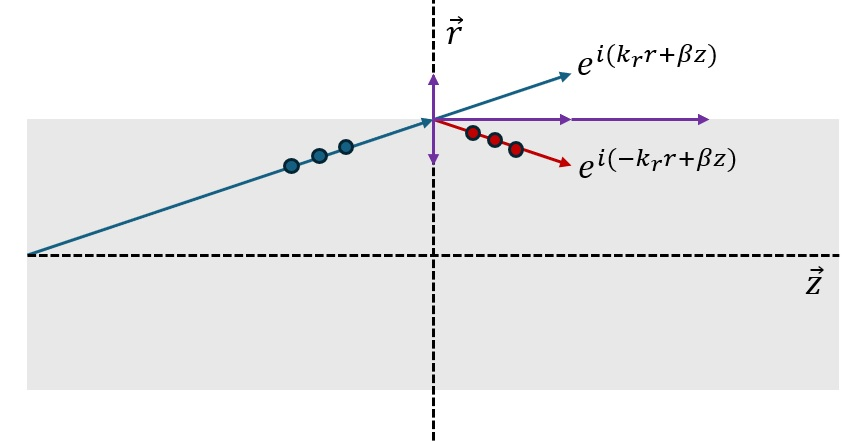

도파관 안의 모드는 축 방향 성분 $\beta$를 공유하면서 횡방향으로 서로 다른 방위각 방향을 갖는 평면파 성분들의 중첩으로 직관적으로 이해할 수 있다. 하나의 성분만 보면, 예를 들어

$$
\mathbf{k}=k_r\hat r+\beta \hat z
$$

처럼 쓸 수 있다. 균일 매질 속의 평면파에서는

$$
\mathbf{E}\cdot \mathbf{k}=0
$$

이므로 전기장은 $\mathbf{k}$에 수직이어야 한다. 원통좌표의 직관에서는 이러한 횡방향 성분으로 $\hat\phi$ 방향의 전기장을 생각하면 $\hat r$에도 $\hat z$에도 직교하므로, TE적인 편광을 떠올리기 쉽다.

그림처럼 하나의 횡방향에서 반사를 생각하면, 그 방향의 파수 성분은

$$
k_r\rightarrow -k_r
$$

가 되지만, $\beta$는 변하지 않는다. 원래 그림의 기호를 유지하여, 선택한 한 반지름 방향에서 두 성분을 비교하자. 두 성분의 진폭을 같게 놓고 상대위상차를 생략하면

$$
e^{i(k_r r+\beta z)}+e^{i(-k_r r+\beta z)}
=
2\cos(k_r r)e^{i\beta z}
$$

처럼 $\pm k_r$ 성분의 중첩으로부터 횡방향 정상파 구조가 생긴다. 여기서 아래 평균은 크기 자체가 아니라 두 부호 있는 성분 $+k_r$, $-k_r$의 평균을 뜻한다. 이런 의미에서

$$
\langle k_r\rangle=0,\qquad k_r\neq 0
$$

이다. 즉 **평균적으로는 횡방향으로 흐르지 않지만, 횡방향 스케일 자체는 남아 있으며, 그 결과 횡단면 모드 구조가 형성된다**.

여기서 $\cos(k_r r)$는 **한 방향에서 본 1차원적인 예**이다.
아직 횡단면 전체에 대한 원통파의 해를 뜻하지 않는다.
이 중첩은 $H_z$와 같은 스칼라 장 성분의 공간 의존성을 설명하는 것으로 생각하면 된다.

**이제 이 한 방향을 횡단면 안에서 회전시키고, 모든 방위각의 기여를 더해 보자.**
이때 각 파의 위상에는 단순한 거리 $r$ 대신, 관측점 위치를 그 파의 진행 방향으로 투영한 거리가 들어간다.
다음 절에서는 이 과정을 통해 베셀 함수가 나타남을 확인한다.


## 4. 원통 대칭성과 베셀 함수의 등장

앞 절의 코사인 정상파는 서로 반대 방향으로 진행하는 두 평면파를 합친 것이다.
이제 구성 평면파들의 진행 방향을 모든 방위각으로 확장한다.
$\phi$는 **관측점의 방위각**, $\psi$는 **구성 평면파의 횡방향 진행 각도**이다.
관측점 위치를 $\psi$ 방향으로 투영한 거리는 $r\cos(\phi-\psi)$이다.

원통계에서 어떤 방위각 $\psi$ 방향을 향하는 횡파수 벡터를 갖는 평면파 성분은 관측점 $(r,\phi)$에서

$$
e^{i k_r r\cos(\phi-\psi)}
$$

라는 위상 인자를 준다. 공통인 축 방향 인자는 잠시 생략한다. 이를 모든 방위각에 대해 같은 가중치로 중첩하면

$$
\int_0^{2\pi} e^{i k_r r\cos(\phi-\psi)}\,d\psi
$$

가 된다.

베셀 함수의 적분 표현

$$
J_0(k_r r)
=
\frac{1}{2\pi}
\int_0^{2\pi}
e^{i k_r r\cos(\phi-\psi)}\,d\psi
$$

로부터,

$$
\boxed{
\int_0^{2\pi}
e^{i k_r r\cos(\phi-\psi)}\,d\psi
=
2\pi J_0(k_r r)
}
$$

를 얻는다. 반대 방향의 평면파를 짝지으면 허수부는 상쇄되고 앞 절의 코사인 항이 남는다.
따라서 이 적분은 **방향을 바꾼 평면 정상파들을 균일하게 중첩하는 것**과 연결된다.
이미 원형인 $\cos(k_r r)$를 단순히 회전시킨다는 뜻은 아니다.

따라서 **원통 대칭적인 평면파 중첩으로부터 $J_0$가 자연스럽게 나타난다**.
관측점을 $\phi=0$ 방향에 두면, 원래의 코사인 표현으로도 같은 결과를 쓸 수 있다.

$$
\frac{1}{2\pi} \int_0^{2\pi}
\cos\!\left[k_r r\cos(-\psi)\right]\,d\psi =J_0(k_r r)
$$

또한 방위각 모드수 $l$을 갖는 성분을 만들려면 각 평면파 성분에 대해 방위각 $\psi$에 의존하는 위상 가중치

$$
e^{il\psi}
$$

를 곱해 중첩하면 된다. 그 결과,

$$
\boxed{
\int_0^{2\pi}
e^{il\psi}
e^{i k_r r\cos(\phi-\psi)}
\,d\psi
=
2\pi i^l J_l(k_r r)e^{il\phi}
}
$$

가 된다. 이는 Jacobi–Anger 전개

$$
e^{iz\cos\theta}
=
\sum_{m=-\infty}^{\infty}
i^m J_m(z)e^{im\theta}
$$

의 직접적인 귀결이며, **평면파의 중첩이 원통파 $J_l(k_r r)e^{il\phi}$를 만든다**는 것을 보여 준다.

이 절의 적분은 스칼라 공간 함수에 대한 관계이다. 이를 전기장 벡터 전체에 바로 적용하지 않고, 다음 절에서는 $H_z$의 분포와 연결한다.

출처: [NIST DLMF, 베셀 적분식 (10.9.1)](https://dlmf.nist.gov/10.9#E1), [Jacobi–Anger 전개](https://dlmf.nist.gov/10.12).


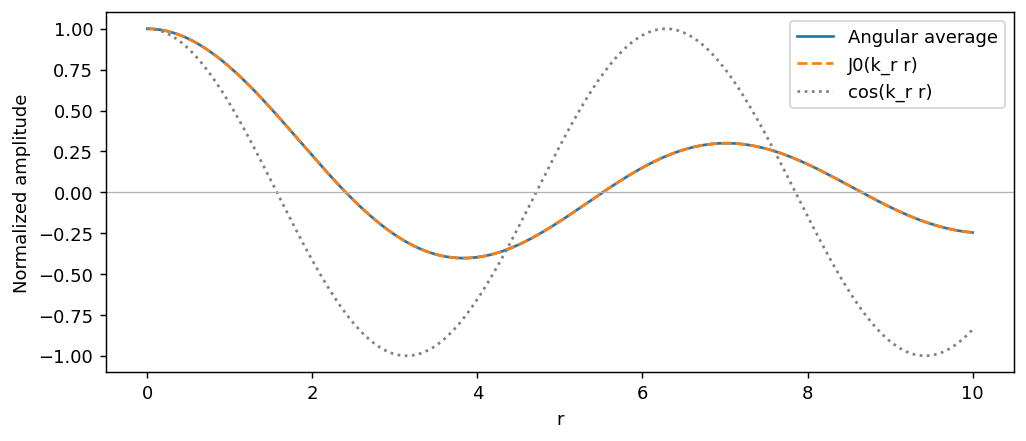

In [2]:
# 4절: 모든 방향의 코사인 평균과 J0를 비교한다.
N = 128  # 방향 개수: 4, 16, 128로 바꿔 보세요.
psi = np.linspace(0, 2*np.pi, N, endpoint=False)
mean_wave = np.cos(k_r * r[:, None] * np.cos(psi)).mean(axis=1)

plt.figure(figsize=(8, 3.5))
plt.plot(r, mean_wave, label="Angular average")
plt.plot(r, j0(k_r*r), "--", label="J0(k_r r)")
plt.plot(r, np.cos(k_r*r), ":", color="0.5", label="cos(k_r r)")
plt.axhline(0, color="0.7", linewidth=0.7)
plt.xlabel("r")
plt.ylabel("Normalized amplitude")
plt.legend()
plt.tight_layout()
plt.show()


## 5. TE 모드의 베셀 함수 표현

원형 도파관의 TE 모드에서는 $E_z=0$이고, 종방향 자기장 $H_z$가 기본이 된다. 원형 도파관에서 쓰이는 종방향 자기장의 베셀 함수 표현은

$$
H_z(r,\phi,z)
=
H_0\,J_l(k_c r)\,[A\cos(l\phi)+B\sin(l\phi)]\,e^{-i\beta z}
$$

의 형태로 쓸 수 있다. 복소수 표시를 사용하면

$$
H_z(r,\phi,z)\propto J_l(k_c r)e^{il\phi}e^{-i\beta z}
$$

라고 써도 된다. 아래에서는 원문처럼 축 방향 인자를 $e^{-i\beta z}$로 표기하며, 횡방향 공간 분포에 집중한다. 여기서 $k_c$는 횡방향의 고유 파수이며, 경계 조건에 의해 양자화된다.

이 일반식을 광섬유의 모든 $l$에 대한 순수 TE 모드로 해석해서는 안 된다.
여기서는 광섬유의 **축대칭 $TE_{0m}$ 모드**, 즉 $l=0$인 경우에 집중한다.
허용되는 파수는 코어와 외부 매질의 경계에서 $H_z$와 $E_\phi$를 연속으로 연결하여 정한다.
자세한 경계방정식 계산은 여기서 다루지 않는다.

참고로 원문에 있던

$$
J_l'(k_c a)=0
$$

과 “지배 모드는 $TE_{11}$”이라는 설명은 **완전도체 벽을 가진 원형 도파관**에 해당한다.
이 조건을 광섬유에 그대로 적용하지 않는다.

출처: [UT Austin, 유전체 도파관의 TE 장과 경계조건, 식 (1386)–(1396)](https://farside.ph.utexas.edu/teaching/jk1/Electromagnetism/node118.html#:~:text=For%20a%20TE%20mode).


## 6. $TE_{0m}$에서 $E_\phi\propto J_1$이 나타나는 이유

축대칭 TE 모드에서는 $l=0$이므로 종방향 자기장은

$$
H_z(r,z)\propto J_0(k_c r)e^{-i\beta z}
$$

가 된다.

TE 모드의 횡전기장 성분은 Maxwell 방정식으로부터 $H_z$의 반지름 방향 미분으로 결정되며, 특히 축대칭인 경우에는

$$
E_\phi \propto -\frac{\partial H_z}{\partial r}
$$

가 된다. 따라서

$$
E_\phi
\propto
-\frac{\partial}{\partial r}J_0(k_c r)
$$

이다. 여기서 베셀 함수의 미분 공식

$$
\frac{dJ_0(x)}{dx}=-J_1(x)
$$

을 사용하면

$$
E_\phi\propto J_1(k_c r)
$$

를 얻는다. 그러므로 $TE_{0m}$에서는 종방향 자기장이 $J_0$형이더라도, 횡전기장 $E_\phi$는 $J_1$형이 된다.

여기서 비례식은 공통 계수와 위상 인자를 생략하고 **반지름 방향의 모양**을 비교한 것이다.
$E_\phi$에 $J_1$이 나타난다고 해서 방위각 모드수가 $l=1$로 바뀌는 것은 아니다.

출처: [NIST DLMF, 미분 공식 (10.6.3)](https://dlmf.nist.gov/10.6#E3).


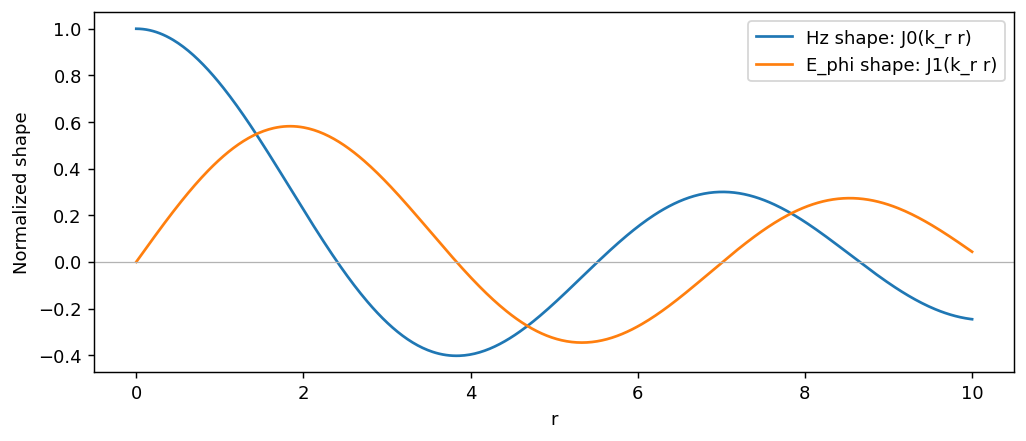

In [3]:
# 6절: 공통 계수를 제외한 Hz와 E_phi의 공간 분포를 비교한다.
plt.figure(figsize=(8, 3.5))
plt.plot(r, j0(k_r*r), label="Hz shape: J0(k_r r)")
plt.plot(r, j1(k_r*r), label="E_phi shape: J1(k_r r)")
plt.axhline(0, color="0.7", linewidth=0.7)
plt.xlabel("r")
plt.ylabel("Normalized shape")
plt.legend()
plt.tight_layout()
plt.show()


## 7. $l$의 의미

종방향 자기장의 복소수 표시

$$
H_z(r,\phi,z)\propto J_l(k_r r)e^{il\phi}e^{-i\beta z}
$$

에서 $l$은 **방위각 모드수**이다.

- $l=0$이면 $e^{i0\phi}=1$이므로 이 스칼라 장 성분은 방위각 $\phi$에 의존하지 않는다.
- $l=1$이면 $e^{i\phi}$이며, $\phi$를 $2\pi$만큼 돌리면 복소 위상은 $2\pi$ 변한다.
- $l=2$이면 $e^{i2\phi}$이며, 한 바퀴에서 복소 위상은 $4\pi$ 변한다.

이런 의미에서 $l$은 복소수 표시에서는 “위상의 감김수”에 대응하는 것처럼 보인다. 그러나 원형 도파관의 일반적인 TE/TM 모드에서는 종종

$$
\cos(l\phi),\qquad \sin(l\phi)
$$

라는 실함수 표시로 쓰이므로, 가장 안전한 명칭은 **방위각 모드수**이다. 즉 $l$은 **편광 방향**을 나타내는 양이 아니라, **횡단면 안에서의 각도 의존성의 차수**를 나타내는 양이다.

축대칭 TE 모드의 전기장은 $\hat{\boldsymbol\phi}$ 방향이다. 성분 $E_\phi(r)$는 방위각에 독립적이어도, 벡터 방향은 원주를 따라 달라진다.


## 8. 요약

이상을 정리하면, 이 글에서 다룬 TE 모드는

$$
E_z=0,\qquad H_z\neq 0
$$

을 만족하는 모드이며, 횡방향 구조는 평면파 성분의 중첩으로 이해할 수 있다. 그 원통 대칭적인 중첩의 결과로 반지름 방향 의존성은 베셀 함수 $J_l$로 표현된다. 특히 모든 방위각에 대한 등가중 중첩에서는 $J_0$가 나타나고, 방위각에 위상 가중치 $e^{il\psi}$를 주면 $J_l(k_r r)e^{il\phi}$가 나타난다. 축대칭 TE 모드에서는 종방향 자기장 $H_z$가 기본이 되며, $TE_{0m}$에서는 $H_z\propto J_0$이고, 거기서 도출되는 횡전기장은

$$
E_\phi\propto J_1
$$

가 된다. 따라서 $l$은 편광을 나타내는 것이 아니라 **모드의 방위각 의존성을 나타내는 지표**이다.
